# 任务 22：LocalGLMnet 的 group LASSO 与变量选择

数据：已从 [CASdatasets 官方仓库](https://github.com/dutangc/CASdatasets) 下载 `freMTPL2freq` 与 `freMTPL2sev`，转换成 `data/*.csv`。对应 OpenML 数据号为 [41214](https://www.openml.org/d/41214) 与 [41215](https://www.openml.org/d/41215)。清洗遵循[教材附录 Listing 13.1](https://link.springer.com/chapter/10.1007/978-3-031-12409-9_13)：从赔款表重算索赔次数、删去超过 5 次索赔的保单、Exposure 截断至 1。模型和解释遵循[第 11 章 §11.5.5](https://link.springer.com/chapter/10.1007/978-3-031-12409-9_11)。

运行环境：`/opt/anaconda3/envs/myenv/bin/python`，需 `torch pandas scikit-learn matplotlib nbformat`。全量训练耗时较长；`MAX_ROWS=None` 使用全部保单，可设整数作调试。固定随机种子；结果不保证与教材完全一致。

In [1]:
from pathlib import Path
import copy, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_poisson_deviance
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED=22; MAX_ROWS=None; EPS=1e-5
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(8, torch.get_num_threads()))
DEVICE='mps' if torch.backends.mps.is_available() else 'cpu'
print('device:',DEVICE)

device: mps


## 1. 清洗与预处理

两个类别变量采用 `drop_first=True` 哑编码：`VehBrand` 11 类变 10 列，`Region` 22 类变 21 列。`Area` 视为有序等级，`VehGas` 为二值。连续/二值 7 列均标准化，`Density` 先取自然对数。标准化参数只在训练集估计。

In [2]:
data=Path('data')
freq=pd.read_csv(data/'freMTPL2freq.csv')
sev=pd.read_csv(data/'freMTPL2sev.csv')
print('raw:',freq.shape,sev.shape)
assert {'IDpol','ClaimNb','Exposure','VehBrand','Region'}.issubset(freq.columns)
assert {'IDpol','ClaimAmount'}.issubset(sev.columns)
# 每一赔款记录代表一次索赔；聚合后与频率表按保单号合并。
counts=sev.groupby('IDpol').size().rename('ClaimNb_corrected')
df=freq.drop(columns='ClaimNb').join(counts,on='IDpol')
df['ClaimNb']=df['ClaimNb_corrected'].fillna(0).astype('int32')
df=df.drop(columns='ClaimNb_corrected')
df=df.loc[(df.ClaimNb<=5)&(df.Exposure>0)].copy()
df['Exposure']=df.Exposure.clip(upper=1)
print('clean:',df.shape,'claims:',df.ClaimNb.sum(),'exposure:',df.Exposure.sum())
if MAX_ROWS is not None: df=df.sample(n=min(MAX_ROWS,len(df)),random_state=SEED).copy()


raw: (677991, 12) (26444, 2)
clean: (677985, 12) claims: 26383 exposure: 358342.1954629838


In [3]:
single=['Area','VehPower','VehAge','DrivAge','BonusMalus','VehGas','Density']
X=pd.DataFrame(index=df.index)
X['Area']=df.Area.astype(str).str.extract(r'([A-F])',expand=False).map({v:i+1 for i,v in enumerate('ABCDEF')}).astype(float)
for col in ['VehPower','VehAge','DrivAge','BonusMalus']: X[col]=pd.to_numeric(df[col])
X['VehGas']=(df.VehGas.astype(str).str.lower()=='regular').astype(float)
X['Density']=np.log(pd.to_numeric(df.Density).clip(lower=1))
brand=pd.get_dummies(df.VehBrand.astype(str),prefix='VehBrand',drop_first=True,dtype=float)
region=pd.get_dummies(df.Region.astype(str),prefix='Region',drop_first=True,dtype=float)
assert brand.shape[1]==10 and region.shape[1]==21,(brand.shape,region.shape)
X=pd.concat([X,brand,region],axis=1)
assert X.shape[1]==38 and X.notna().all().all()
idx_train,idx_test=train_test_split(np.arange(len(df)),test_size=.2,random_state=SEED)
idx_train,idx_val=train_test_split(idx_train,test_size=.2,random_state=SEED)
scaler=StandardScaler().fit(X.iloc[idx_train])
Z=scaler.transform(X).astype('float32')
y=df.ClaimNb.to_numpy(dtype='float32'); vol=df.Exposure.to_numpy(dtype='float32')
print('groups:',[1]*7+[10,21],'shape:',Z.shape)

groups: [1, 1, 1, 1, 1, 1, 1, 10, 21] shape: (677985, 38)


## 2. 38×9 分组矩阵与光滑惩罚

$W_{jk}=1$ 表示第 $j$ 列属于组 $k$。$\eta_k=\eta\sqrt{q_k}$。惩罚为 $\eta\sum_k\sqrt{q_k}\sqrt{\sum_{j\in G_k}\beta_j(x)^2+\epsilon}$。光滑范数在零处为 $\sqrt\epsilon$，所以无法产生精确零。

(38, 9) [[1.        1.        1.        1.        1.        1.        1.
  3.1622777 4.582576 ]]


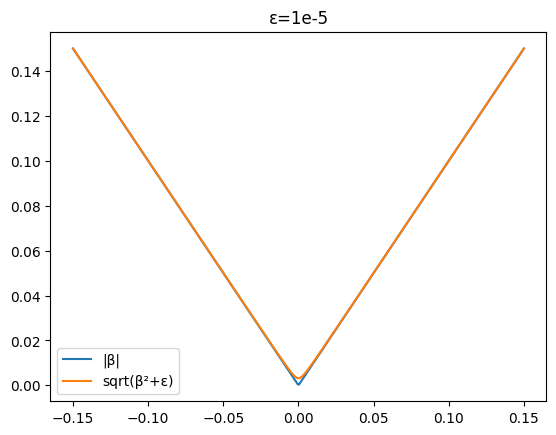

In [4]:
sizes=[1]*7+[10,21]
ww=np.zeros((38,9),dtype='float32')
start=0
for k,size in enumerate(sizes): ww[start:start+size,k]=1; start+=size
assert np.all(ww.sum(axis=1)==1)
etaK=np.sqrt(np.array(sizes,dtype='float32')).reshape(9,1)
print(ww.shape,etaK.T)
t=np.linspace(-.15,.15,400)
plt.plot(t,np.abs(t),label='|β|'); plt.plot(t,np.sqrt(t*t+EPS),label='sqrt(β²+ε)')
plt.legend(); plt.title('ε=1e-5'); plt.show()

## 3. 网络与泊松偏差

Attention：38 → 15 (`tanh`) → 10 (`tanh`) → 38（线性）。输出 `exp(bias + Σ x_j β_j(x) + log Exposure)`。泊松偏差使用 $2[y\log(y/\hat\lambda)-(y-\hat\lambda)]$，其中 $y=0$ 时首项为 0。

In [5]:
class LocalGLMnet(nn.Module):
    def __init__(self,eta):
        super().__init__()
        self.attention=nn.Sequential(nn.Linear(38,15),nn.Tanh(),nn.Linear(15,10),nn.Tanh(),nn.Linear(10,38))
        self.bias=nn.Parameter(torch.tensor(-2.6))
        self.register_buffer('ww',torch.tensor(ww))
        self.register_buffer('etaK',torch.tensor(etaK[:,0]*eta))
    def forward(self,x,exposure):
        beta=self.attention(x)
        penalty=torch.sqrt(beta.square()@self.ww+EPS)@self.etaK
        log_mu=self.bias+(x*beta).sum(1)+exposure.log()
        return torch.exp(log_mu.clamp(-15,12)),penalty,beta

def deviance(y,pred):
    safe_y=torch.where(y>0,y,torch.ones_like(y))
    return 2*(torch.where(y>0,y*torch.log(safe_y/pred.clamp_min(1e-12)),torch.zeros_like(y))-y+pred)

def fit_model(Z,y,vol,eta,train_idx=idx_train,val_idx=idx_val,epochs=25,batch=4096,patience=4):
    model=LocalGLMnet(eta).to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=.002)
    ds=TensorDataset(torch.from_numpy(Z[train_idx]),torch.from_numpy(y[train_idx]),torch.from_numpy(vol[train_idx]))
    loader=DataLoader(ds,batch_size=batch,shuffle=True)
    xv=torch.from_numpy(Z[val_idx]).to(DEVICE); yv=torch.from_numpy(y[val_idx]).to(DEVICE); vv=torch.from_numpy(vol[val_idx]).to(DEVICE)
    best=float('inf'); stale=0; history=[]
    for epoch in range(epochs):
        model.train()
        for xb,yb,vb in loader:
            xb,yb,vb=xb.to(DEVICE),yb.to(DEVICE),vb.to(DEVICE)
            opt.zero_grad(); pred,pen,_=model(xb,vb)
            loss=(deviance(yb,pred)+pen).mean(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),5); opt.step()
        model.eval()
        with torch.no_grad():
            scores=[]
            for a in range(0,len(xv),batch):
                pred,pen,_=model(xv[a:a+batch],vv[a:a+batch])
                scores.append((deviance(yv[a:a+batch],pred)+pen).sum().item())
            score=sum(scores)/len(xv)
        history.append(score)
        print(f'η={eta:.4f} epoch={epoch+1} val_objective={score:.5f}')
        if score<best-1e-5: best=score; state=copy.deepcopy(model.state_dict()); stale=0
        else: stale+=1
        if stale>=patience: break
    model.load_state_dict(state)
    return model,history

def infer(model,Z,vol,batch=8192):
    model.eval(); preds=[]; abs_betas=[]
    with torch.no_grad():
        for a in range(0,len(Z),batch):
            x=torch.from_numpy(Z[a:a+batch]).to(DEVICE)
            v=torch.from_numpy(vol[a:a+batch]).to(DEVICE)
            pred,_,beta=model(x,v)
            preds.append(pred.cpu().numpy()); abs_betas.append(beta.abs().cpu().numpy())
    return np.concatenate(preds),np.concatenate(abs_betas).mean(axis=0)


## 4. 三种正则强度

使用同一训练/验证/测试划分。早停监控含惩罚的验证目标；最终比较采用无惩罚的测试集泊松偏差。所有重要性都在**测试集**计算，以减少训练样本偏倚。

In [6]:
etas=[0.,.0025,.005]
models={}; importance={}; metrics=[]
for eta in etas:
    torch.manual_seed(SEED)
    model,hist=fit_model(Z,y,vol,eta)
    pred,im=infer(model,Z[idx_test],vol[idx_test])
    models[eta]=model; importance[eta]=im
    metrics.append({'eta':eta,'best_epoch':int(np.argmin(hist)+1),'test_deviance':mean_poisson_deviance(y[idx_test],pred),'test_frequency':pred.sum()/vol[idx_test].sum()})
pd.DataFrame(metrics)

η=0.0000 epoch=1 val_objective=0.24303


η=0.0000 epoch=2 val_objective=0.24171


η=0.0000 epoch=3 val_objective=0.24117


η=0.0000 epoch=4 val_objective=0.24073


η=0.0000 epoch=5 val_objective=0.24099


η=0.0000 epoch=6 val_objective=0.24119


... (38 outputs left out)

η=0.0050 epoch=17 val_objective=0.24415


η=0.0050 epoch=18 val_objective=0.24381


η=0.0050 epoch=19 val_objective=0.24402


,eta,best_epoch,test_deviance,test_frequency
0,0.0000,4,0.245162,0.073951
1,0.0025,16,0.244587,0.074391
2,0.0050,15,0.244910,0.073977


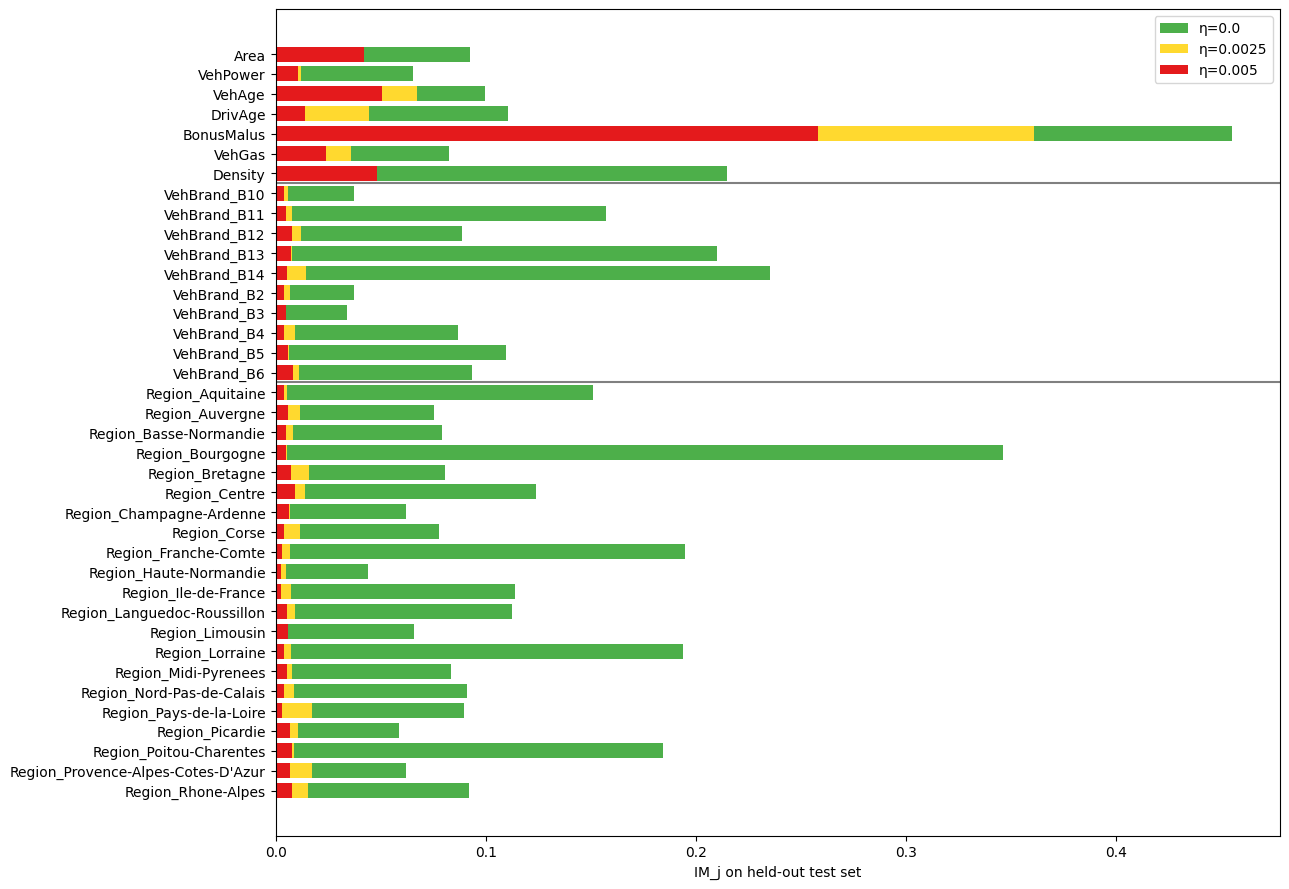

             IM_0025    IM_005
group                         
VehBrand    0.008824  0.005620
Region      0.009775  0.005316
VehPower    0.011859  0.010746
Area        0.030769  0.042070
VehGas      0.035908  0.024035
Density     0.042030  0.048473
DrivAge     0.044493  0.013783
VehAge      0.067472  0.050547
BonusMalus  0.360864  0.258326


In [7]:
fig,ax=plt.subplots(figsize=(13,9))
order=np.arange(38)
# 同心叠置显示三组绝对重要性；若排序未随 η 单调变化，颜色并非严格的“增量”。
for eta,color in [(0.,'#4daf4a'),(.0025,'#ffd92f'),(.005,'#e41a1c')]:
    ax.barh(order,importance[eta],color=color,label=f'η={eta}',height=.75)
ax.set_yticks(order,X.columns); ax.invert_yaxis(); ax.legend(); ax.set_xlabel('IM_j on held-out test set')
ax.axhline(6.5,color='0.5'); ax.axhline(16.5,color='0.5'); plt.tight_layout(); plt.show()
summary=pd.DataFrame({'component':X.columns,'group':single+['VehBrand']*10+['Region']*21,'IM_0':importance[0.], 'IM_0025':importance[.0025], 'IM_005':importance[.005]})
print(summary.groupby('group')[['IM_0025','IM_005']].mean().sort_values('IM_0025'))

## 5. `Region` 整组置换阴性对照

仅打乱 `Region` 标签，保持每条记录的其他特征、索赔和 Exposure 不变。使用同一划分、相同预处理规则和同样的超参数重新训练。这里固定一次置换；它是阴性对照，不构成有 $p$ 值的经典置换检验。

η=0.0000 epoch=1 val_objective=0.24426


η=0.0000 epoch=2 val_objective=0.24233


η=0.0000 epoch=3 val_objective=0.24163


η=0.0000 epoch=4 val_objective=0.24137


η=0.0000 epoch=5 val_objective=0.24175


η=0.0000 epoch=6 val_objective=0.24178


... (33 outputs left out)

η=0.0050 epoch=17 val_objective=0.24441


η=0.0050 epoch=18 val_objective=0.24446


η=0.0050 epoch=19 val_objective=0.24466


η=0.0050 epoch=20 val_objective=0.24452
permuted Region mean IM: 0.009341113


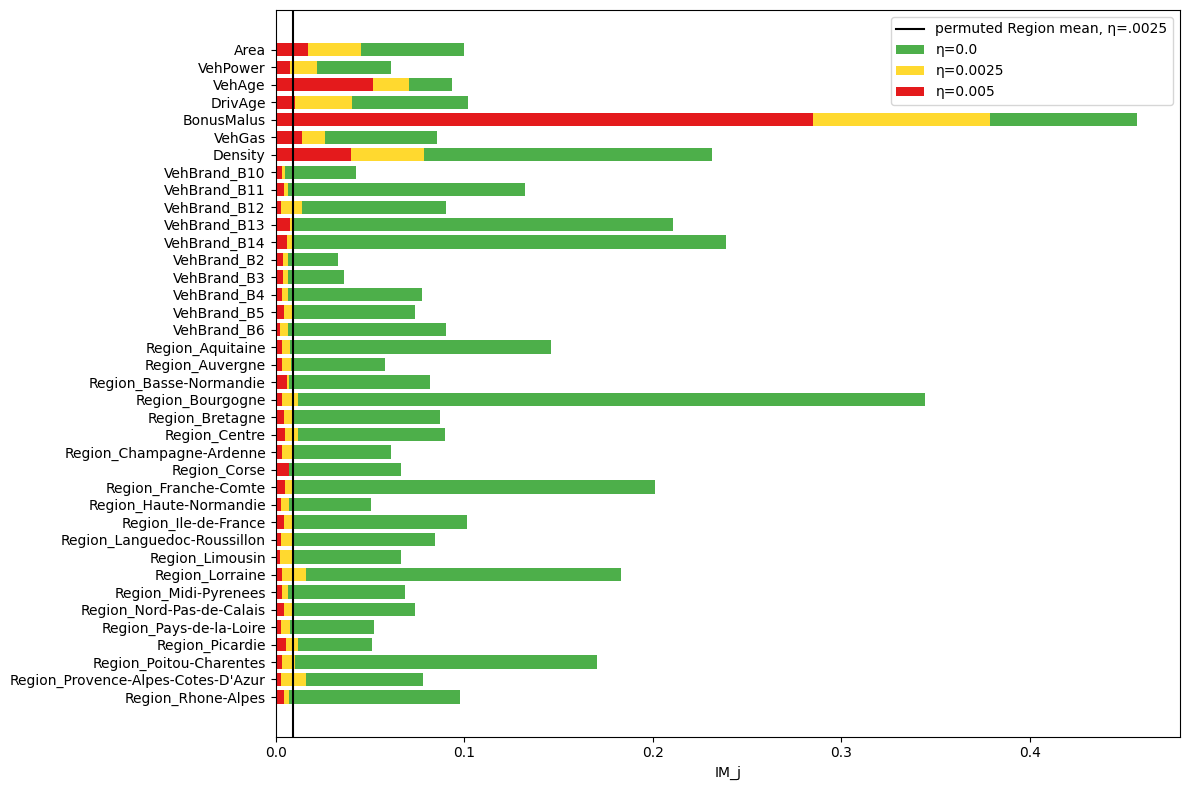

original groups below control: group
VehBrand    0.008824
Name: IM_0025, dtype: float32


In [8]:
rng=np.random.default_rng(SEED+1)
permuted=df.Region.to_numpy()[rng.permutation(len(df))]
X_perm=X.copy()
R=pd.get_dummies(pd.Series(permuted,index=X.index).astype(str),prefix='Region',drop_first=True,dtype=float)
R=R.reindex(columns=region.columns,fill_value=0.)
X_perm.loc[:,region.columns]=R.to_numpy()
scaler_perm=StandardScaler().fit(X_perm.iloc[idx_train])
Z_perm=scaler_perm.transform(X_perm).astype('float32')
perm_models={}; perm_importance={}
for eta in etas:
    torch.manual_seed(SEED)
    model,_=fit_model(Z_perm,y,vol,eta)
    _,im=infer(model,Z_perm[idx_test],vol[idx_test])
    perm_models[eta]=model; perm_importance[eta]=im
control=perm_importance[.0025][17:].mean()
print('permuted Region mean IM:',control)
fig,ax=plt.subplots(figsize=(12,8))
for eta,color in [(0.,'#4daf4a'),(.0025,'#ffd92f'),(.005,'#e41a1c')]:
    ax.barh(np.arange(38),perm_importance[eta],color=color,label=f'η={eta}',height=.75)
ax.axvline(control,color='black',label='permuted Region mean, η=.0025')
ax.set_yticks(np.arange(38),X.columns); ax.invert_yaxis(); ax.legend(); ax.set_xlabel('IM_j'); plt.tight_layout(); plt.show()
print('original groups below control:',summary.groupby('group').IM_0025.mean().loc[lambda s:s<control])

## 6. 结果判读

运行上方单元后依据输出确认，而不要把教材图中的排序当成必然复现。特别检查：`VehPower` 是否为 7 个单列组最小、`Region` 的平均 IM 是否高于 `VehBrand`、两个类别组是否高于置换对照。不同随机种子、早停和数据清洗细节会影响排序。若需要正式显著性结论，应重复置换与训练并构造零分布。`IM` 是注意力系数的绝对均值，不能单独解释对预测的因果贡献；也可补充删除组后测试偏差变化。

## 6.1 本次全量运行的实际结果（seed=22）

清洗后 677,985 条保单、26,383 次索赔，输入为 38 列。测试集平均泊松偏差：η=0 为 **0.245162**，η=.0025 为 **0.244587**，η=.005 为 **0.244910**；三者接近，不能据此宣称正则化网络显著改善预测。

η=.0025 下，`VehPower` 的 IM 为 **0.011859**，是七个单列组中最小的。`Region` 组平均 IM **0.009775**，略高于 `VehBrand` 的 **0.008824**，但两个类别组平均值均低于 `VehPower`。置换后 `Region` 组平均 IM **0.009341**；按组均值比较，原数据中 `VehBrand` 低于该对照，而 `VehPower` 高于它。因此，本次实现**没有复现**教材“仅 VehPower 低于置换 Region”的排序。参考类选择、编码、损失尺度、随机初始化与训练早停都会影响 IM；一次置换也不足以支持正式的显著性判定。报告中应呈现本次结果与教材结论的差异，不应把教材描述写成实测结论。

## 7. 延伸追问回答

1. **ε 近似取舍**：$\|\beta\|_2$ 在零向量不可微；普通梯度下降无法在那里定义唯一梯度，虽可用次梯度或近端算法。$\sqrt{\|\beta\|_2^2+\epsilon}$ 提供平滑梯度 $\beta/\sqrt{\|\beta\|_2^2+\epsilon}$。ε 越小越接近尖点、越促使小组变小，但零附近曲率增大，优化更敏感；ε 越大更稳定，但稀疏性更弱。光滑罚不会精确置零。
2. **二次拟合**：先筛组，再只用保留组以无罚损失拟合，可减轻收缩偏差、改善校准与预测；但解除收缩会增加方差，筛选若不稳定还会过拟合。需用独立验证集选择/评估，不能用测试集调参。
3. **组与逐分量**：逐分量 LASSO 可能只留某些类别水平，结果随参考类改变；组罚将整个因子共同处理。$\sqrt{q_k}$ 让大组因维度带来的典型范数增长得到补偿，避免大组天然享有过低的单位组惩罚；它不是完全消除编码或组内相关性的影响。
4. **预测竞争力**：稀疏哑变量使一些类别水平样本少且参数较多，网络迅速拟合训练噪声，验证损失提早上升，早停可能在整体结构尚未学好时触发。可试更宽泛的耐心、权重衰减、组内共享表示/embedding、减少稀有水平、交叉验证 η，并比较独立测试偏差。完整 one-hot 会多两个冗余列且与截距共线，不能自动解决过拟合；若用 one-hot 须重新定义组维度与可识别性约束。
5. **IM**：$|\beta_j(x_i)|$ 汇总局部斜率幅度，平均后给出全局描述；标准化让不同列较可比。GLM 只有固定 $|\beta_j|$，LocalGLMnet 的 $\beta_j(x)$ 随保单变化。但 IM 不反映符号、变量出现频率、相关性、组内类别编码或对预测的实际增量，需配合敏感度和删组验证。
6. **置换逻辑**：置换切断 `Region` 与响应及其他特征的原有配对，再完整拟合，提供网络在无真实 `Region` 信号时仍可能赋予它的基线重要性。与经典置换检验相似之处是构造零信号参考；一次置换无 $p$ 值，且协变量相关时直接置换会破坏联合分布，不能当严格条件独立检验。它也等价于引入随机分量作阴性对照的思路。
7. **双重印证**：$I_\alpha$ 检查局部注意力分布区间，group LASSO 观察惩罚后的幅度；两者统计机制不同，结论一致可提高筛选结论的稳健信心，但共享数据和架构，不能视作独立证据或证明因果无效。
8. **Region 与 VehBrand**：地理差异可能反映路况、交通密度、气候、理赔环境；品牌可能反映车型、驾驶群体及使用方式。这里的 IM 排序是模型与编码条件下的关联，不能单凭它断言机制。若与 GLM 结论比较，需在相同清洗、特征与保单划分上做整组似然比/偏差增量；若排序一致才称一致。
9. **η 选择**：η=0 为无罚基线；.0025 与 .005 依次提高收缩。选变量可看重要性排序和跨种子稳定性；选预测模型应在训练集内部交叉验证或验证集选 η，再在独立测试集报告无罚偏差。只比较三点较粗，可扩展对数网格，且每个 η 的早停规则必须一致。
10. **四者统一**：注意力网络产生随输入变化的 $\beta_j(x)$，实现非线性；每个 $\beta_j$ 依赖全体输入而产生交互；$\sum_jx_j\beta_j(x)$ 保留局部系数式解释；组罚压低整组注意力以辅助变量选择。监管沟通可展示分组、局部效应和敏感度；仍需稳定性、校准、公平性、分布漂移及数据处理审计。光滑惩罚仅给近零组，最终删除与二次拟合要单独实施。